<div style="padding: 1.25rem 1.4rem; border-radius: 14px; background: linear-gradient(120deg,#091126,#16284F); color: white;">
  <div style="font-size:0.78rem; letter-spacing:0.12em; text-transform:uppercase; color:#A1E2DD;">Calentamiento · Ecuaciones diferenciales y computación clásica</div>
  <h1 style="color:white; margin:0.55rem 0 0.35rem 0;">El método de Euler: de la pendiente a la solución numérica</h1>
</div>


# 

**Objetivo.** Entender cómo se aproxima la solución de una ecuación diferencial ordinaria (EDO), aplicar el procedimiento al oscilador armónico y reconocer qué puede salir mal cuando se discretiza la evolución con un paso temporal inadecuado.

El notebook está organizado en tres bloques:

1. Idea y fórmula del método de Euler.
2. Oscilador armónico: solución analítica frente a solución numérica.
3. Limitaciones generales de la integración numérica paso a paso, ilustradas con un ejemplo de enfriamiento.

> **Idea central:** conocer la pendiente en un instante permite estimar cómo cambiará la solución durante un pequeño intervalo de tiempo. Repetir esa estimación construye una trayectoria aproximada.

# 1. ¿En qué consiste el método de Euler?

Consideremos una EDO con condición inicial:

$$
\frac{dy}{dt}=f(t,y), \qquad y(t_0)=y_0.
$$

La ecuación nos dice que la pendiente de la solución en cada punto $(t,y)$ es $f(t,y)$. Si estamos en $(t_n,y_n)$ y avanzamos un intervalo pequeño $h$, podemos aproximar la curva por su recta tangente:

$$
y_{n+1}\approx y_n+h\,f(t_n,y_n).
$$

Esta es la **regla de Euler**:

$$
\boxed{\begin{aligned}
t_{n+1}&=t_n+h,\\
y_{n+1}&=y_n+h\,f(t_n,y_n).
\end{aligned}}
$$

- $h$ es el **paso temporal**: cuánto avanzamos en cada iteración.
- $f(t_n,y_n)$ es la pendiente en el punto actual.
- La nueva estimación se obtiene avanzando una distancia horizontal $h$ siguiendo esa pendiente.

El proceso se repite: cada nuevo punto se convierte en el punto de partida del siguiente paso.

**Intuición geométrica.** En cada paso sustituimos, durante un intervalo corto, la curva desconocida por su tangente. Cuanto más pequeño sea $h$, más corta es esa extrapolación. Esto suele mejorar la aproximación, aunque exige más pasos.

## Implementación matricial

La regla de Euler es una relación entre dos instantes consecutivos. Para un sistema lineal autónomo

$$
\frac{d\mathbf y}{dt}=A\mathbf y,
$$

la regla de Euler toma la forma

$$
\mathbf y_{n+1}=\mathbf y_n+hA\mathbf y_n
=(I+hA)\mathbf y_n.
$$

Definimos $M=I+hA$. En lugar de calcular cada estado mediante un bucle, podemos escribir **todas las ecuaciones de todos los pasos a la vez**. Agrupamos los estados en un único vector:

$$
\mathbf Y=
\begin{pmatrix}
\mathbf y_0\\
\mathbf y_1\\
\mathbf y_2\\
\vdots\\
\mathbf y_N
\end{pmatrix}.
$$

Las relaciones entre pasos son

$$
\begin{aligned}
\mathbf y_0&=\text{condición inicial},\\
-\!M\mathbf y_0+\mathbf y_1&=0,\\
-\!M\mathbf y_1+\mathbf y_2&=0,\\
&\vdots\\
-\!M\mathbf y_{N-1}+\mathbf y_N&=0.
\end{aligned}
$$

Esto equivale a un único sistema lineal:

$$
\underbrace{
\begin{pmatrix}
I&0&0&\cdots&0\\
-M&I&0&\cdots&0\\
0&-M&I&\cdots&0\\
\vdots&\ddots&\ddots&\ddots&\vdots\\
0&\cdots&0&-M&I
\end{pmatrix}}_{\mathcal L}
\begin{pmatrix}
\mathbf y_0\\
\mathbf y_1\\
\mathbf y_2\\
\vdots\\
\mathbf y_N
\end{pmatrix}
=
\begin{pmatrix}
\mathbf y_{\mathrm{inicial}}\\
0\\
0\\
\vdots\\
0
\end{pmatrix}.
$$

La matriz $\mathcal L$ aparece directamente al juntar la condición inicial y las reglas de actualización de Euler. Como es triangular por bloques y tiene la identidad en la diagonal, es invertible. Por tanto,

$$
\boxed{\mathbf Y=\mathcal L^{-1}\mathbf b.}
$$

En el código construiremos esta matriz y calcularemos su inversa. Esta formulación evita los bucles explícitos y permite ver la integración numérica como un problema de álgebra lineal. **Nota:** para cálculos numéricos grandes suele ser más estable resolver $\mathcal L\mathbf Y=\mathbf b$ directamente, en vez de formar la inversa; aquí usamos la inversa porque queremos hacer visible la estructura matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def euler_matrix(A, y0, h, n_steps):
    """Construye la solución de Euler de y' = A @ y mediante una matriz global.

    Devuelve los tiempos y los estados. Cada fila de states es y_n.
    """
    A = np.asarray(A, dtype=float)
    y0 = np.asarray(y0, dtype=float).reshape(-1)

    if h <= 0:
        raise ValueError("El paso h debe ser positivo.")
    if n_steps < 1:
        raise ValueError("n_steps debe ser al menos 1.")

    dimension = y0.size
    identity = np.eye(dimension)
    M = identity + h * A

    # Matriz global construida sin bucles:
    # I_(N+1) ⊗ I_d coloca I en la diagonal de bloques.
    # La matriz de desplazamiento inferior coloca -M justo debajo.
    identity_time = np.eye(n_steps + 1)
    shift_lower = np.diag(np.ones(n_steps), k=-1)
    L = (np.kron(identity_time, identity)
         - np.kron(shift_lower, M))

    # La condición inicial ocupa el primer bloque del vector del lado derecho.
    b = np.zeros((n_steps + 1) * dimension)
    b[:dimension] = y0

    # Resolución explícita mediante la inversa, con finalidad didáctica.
    Y = np.linalg.inv(L) @ b

    # Reorganizamos el vector largo como una sucesión de estados.
    states = Y.reshape(n_steps + 1, dimension)
    times = h * np.arange(n_steps + 1)

    return times, states


Una vez entendido este mecanismo, podemos aplicarlo a un sistema físico.

# 2. Aplicación: el oscilador armónico simple

## 2.1. El modelo físico

Pensemos en una masa $m$ unida a un muelle ideal de constante elástica $k$, sin rozamiento. Si desplazamos la masa una distancia $x$ respecto a su posición de equilibrio, la ley de Hooke establece que la fuerza del muelle es restauradora:

$$
F=-kx.
$$

Por la segunda ley de Newton, $F=m\,d^2x/dt^2$. Por tanto,

$$
m\frac{d^2x}{dt^2}=-kx
\qquad\Longrightarrow\qquad
\frac{d^2x}{dt^2}+\omega^2x=0,
\quad \omega=\sqrt{\frac{k}{m}}.
$$

La aceleración apunta hacia el equilibrio. Cuando la masa está a un lado, el muelle tira de ella hacia el centro; al cruzar el equilibrio, la velocidad hace que continúe hacia el otro lado. Este intercambio entre energía potencial elástica y energía cinética produce la oscilación.

## 2.2. Solución analítica

La solución general de la ecuación es

$$
x(t)=C_1\cos(\omega t)+C_2\sin(\omega t).
$$

Tomemos las condiciones iniciales habituales: desplazamiento inicial $x(0)=A$ y velocidad inicial nula $v(0)=0$. Se obtiene $C_1=A$ y $C_2=0$, luego

$$
\boxed{x_{\mathrm{exacta}}(t)=A\cos(\omega t)}.
$$

La velocidad es la derivada de la posición:

$$
v_{\mathrm{exacta}}(t)=-A\omega\sin(\omega t).
$$

El período de oscilación, es decir, el tiempo que tarda en repetir su movimiento, es $T=2\pi/\omega$.

## 2.3. Escribir la EDO como un sistema de primer orden

El método de Euler se aplica directamente a ecuaciones de primer orden. Para utilizarlo aquí, introducimos la velocidad $v=dx/dt$:

$$
\begin{cases}
\displaystyle \frac{dx}{dt}=v,\\[4pt]
\displaystyle \frac{dv}{dt}=-\omega^2x.
\end{cases}
$$



Para el oscilador, el vector de estado es $\mathbf y=(x,v)^T$. Sus ecuaciones se pueden escribir como una única ecuación matricial:

$$
\frac{d\mathbf y}{dt}
=
\underbrace{
\begin{pmatrix}
0&1\\
-\omega^2&0
\end{pmatrix}}_{A_{\mathrm{sistema}}}
\mathbf y.
$$

La matriz contiene la dinámica física: la primera fila expresa que la velocidad es la derivada de la posición; la segunda, que la aceleración es $-\omega^2x$.

Euler transforma esta ecuación diferencial en la actualización

$$
\mathbf y_{n+1}
=
\left(I+hA_{\mathrm{sistema}}\right)\mathbf y_n.
$$

En vez de aplicar esta relación repetidamente, apilamos las incógnitas de todos los instantes y construimos la matriz global $\mathcal L$ del apartado anterior. Así, resolver la EDO discretizada equivale a invertir una matriz y multiplicarla por el vector que contiene la condición inicial.

## 2.4. Resolverlo numéricamente

Elegimos $m=1\,\mathrm{kg}$, $k=1\,\mathrm{N/m}$ y $A=1\,\mathrm{m}$. Así, $\omega=1\,\mathrm{rad/s}$ y $T=2\pi\,\mathrm{s}$. Partimos del reposo desde el desplazamiento máximo.

El código utiliza la función `euler` definida en el bloque anterior. La función `rhs_oscilador` devuelve las derivadas de la posición y de la velocidad.

In [2]:
# Parámetros físicos del sistema
m = 1.0       # masa, en kg
k = 1.0       # constante del muelle, en N/m
A0 = 1.0      # amplitud inicial, en m
omega = np.sqrt(k / m)
periodo = 2 * np.pi / omega

# Estado y condición inicial: y = (posición, velocidad).
estado_inicial = np.array([A0, 0.0])

# Matriz dinámica: d/dt [x, v]^T = A_sistema [x, v]^T.
A_sistema = np.array([
    [0.0, 1.0],
    [-(omega ** 2), 0.0]
])

# Parámetros de la discretización
h = 0.05
n_periodos = 2
n_steps = int(round(n_periodos * periodo / h))

t_num, estado_num = euler_matrix(
    A=A_sistema,
    y0=estado_inicial,
    h=h,
    n_steps=n_steps
)

x_num = estado_num[:, 0]
v_num = estado_num[:, 1]

# Solución analítica en los mismos instantes.
x_exacta = A0 * np.cos(omega * t_num)
v_exacta = -A0 * omega * np.sin(omega * t_num)


## 2.5. Comparación de las soluciones

En las figuras, la curva continua es la solución analítica y los puntos unidos son las estimaciones numéricas de Euler. Se muestran tanto la posición como la velocidad, porque juntas describen completamente el estado del oscilador.

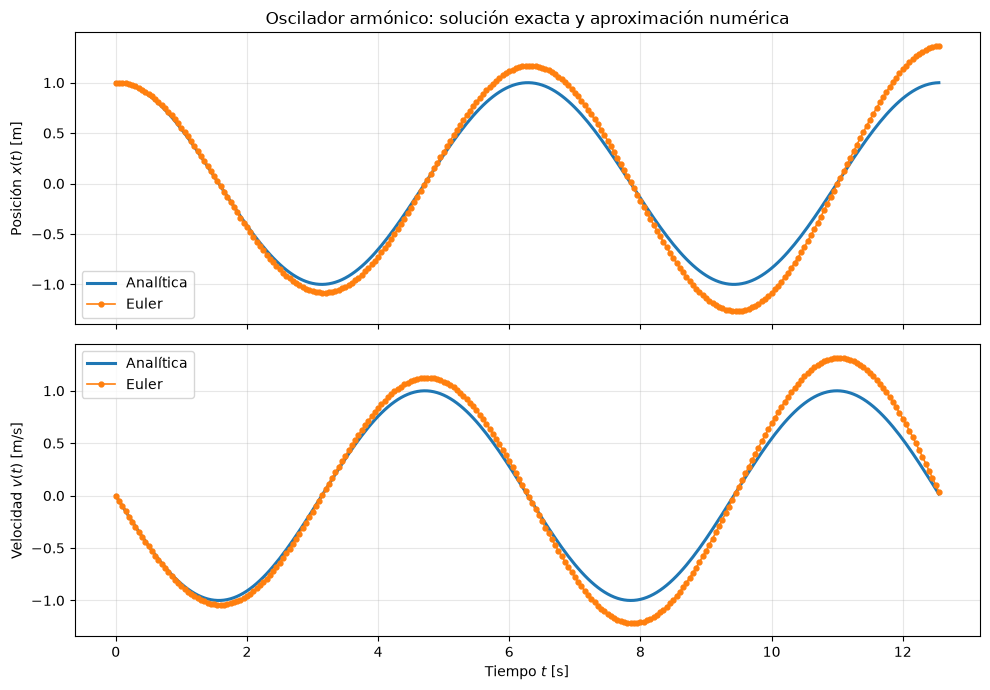

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Comparación de la posición
axes[0].plot(t_num, x_exacta, label="Analítica", linewidth=2.2)
axes[0].plot(t_num, x_num, "o-", label="Euler", markersize=3.5, linewidth=1.2)
axes[0].set_ylabel("Posición $x(t)$ [m]")
axes[0].set_title("Oscilador armónico: solución exacta y aproximación numérica")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Comparación de la velocidad
axes[1].plot(t_num, v_exacta, label="Analítica", linewidth=2.2)
axes[1].plot(t_num, v_num, "o-", label="Euler", markersize=3.5, linewidth=1.2)
axes[1].set_xlabel("Tiempo $t$ [s]")
axes[1].set_ylabel("Velocidad $v(t)$ [m/s]")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación.** La aproximación sigue el movimiento oscilatorio, pero se va separando de la solución exacta. En particular, la amplitud numérica tiende a crecer, aunque el modelo físico ideal mantiene una amplitud constante.

Esto no es un efecto físico del muelle: es un error introducido por la discretización. En el bloque siguiente veremos por qué los errores de este tipo deben analizarse con cuidado y cómo una elección inadecuada del paso puede producir un resultado completamente engañoso.

# 3. Limitaciones de la integración numérica paso a paso

Las limitaciones que siguen no deben entenderse como una lista de defectos exclusivos de una fórmula concreta. Son dificultades generales de los procedimientos que aproximan la evolución continua de una EDO mediante una sucesión de pasos temporales.

## 3.1. ¿Qué puede fallar y por qué?

1. **Error de discretización.** Durante cada intervalo se sustituye la evolución real por una aproximación. Si la solución cambia mucho dentro del paso, la estimación puede ser pobre.
2. **Acumulación del error.** Cada valor aproximado se utiliza para calcular el siguiente. Por tanto, un error cometido al principio puede propagarse y afectar a los pasos posteriores.
3. **Estabilidad numérica.** Una solución física puede decaer o permanecer acotada, pero los errores numéricos pueden amplificarse. El cálculo puede acabar creciendo u oscilando sin que la EDO real lo haga.
4. **Varias escalas temporales.** Si el sistema tiene una dinámica muy rápida junto a otra lenta, el paso debe ser suficientemente pequeño para representar la escala rápida. Esto puede hacer que la simulación resulte costosa.
5. **Propiedades físicas no garantizadas.** La solución exacta puede conservar energía, mantenerse positiva o respetar una cantidad total. Una aproximación numérica no tiene por qué conservar esas propiedades automáticamente.

**Una distinción importante:** reducir el paso suele disminuir el error de discretización, pero no basta con mirar si la curva parece suave. También hay que comprobar si la solución numérica reproduce el comportamiento cualitativo que exige el problema físico.

## 3.2. Ejemplo: enfriamiento de un cuerpo

Imaginemos un objeto a temperatura $T(t)$ dentro de una habitación cuya temperatura ambiente $T_{\mathrm{amb}}$ es constante. La ley de enfriamiento de Newton establece que la rapidez con la que cambia la temperatura es proporcional a la diferencia con el ambiente:

$$
\frac{dT}{dt}=-\frac{T-T_{\mathrm{amb}}}{\tau},
$$

donde $\tau>0$ es la **constante de tiempo** del proceso.

Supongamos que el objeto empieza más caliente que la habitación, $T(0)=T_0>T_{\mathrm{amb}}$. La solución analítica es

$$
\boxed{T_{\mathrm{exacta}}(t)=T_{\mathrm{amb}}+(T_0-T_{\mathrm{amb}})e^{-t/\tau}}.
$$

La física nos dice que la temperatura debe acercarse suavemente a la temperatura ambiente desde arriba. No debe cruzarla ni alejarse de ella.

Aplicando Euler se obtiene

$$
T_{n+1}=T_n-\frac{h}{\tau}(T_n-T_{\mathrm{amb}}).
$$

Si definimos la diferencia respecto al ambiente como $\theta_n=T_n-T_{\mathrm{amb}}$, la actualización queda

$$
\theta_{n+1}=\left(1-\frac{h}{\tau}\right)\theta_n.
$$

Esta expresión permite entender el problema: si $h$ es demasiado grande respecto a $\tau$, el factor puede ser negativo y tener módulo mayor que uno. Entonces la aproximación cruza la temperatura ambiente y, además, se aleja cada vez más. La solución exacta, en cambio, siempre se aproxima al ambiente.

## 3.3. Simulación de un paso demasiado grande

Tomamos una habitación a $20^{\circ}$ C, un objeto que comienza a $30^{\circ}$ C y una constante de tiempo de $60$ s. Elegimos deliberadamente un paso $h=2.2\tau$. El objetivo es mostrar qué ocurre cuando el paso temporal no resuelve la escala característica del fenómeno.

In [4]:
# Parámetros del ejemplo de enfriamiento
T_amb = 20.0       # temperatura ambiente, en °C
T0 = 30.0          # temperatura inicial, en °C
tau = 60.0         # constante de tiempo, en segundos

# Trabajamos con el exceso de temperatura theta = T - T_amb.
# Así, la EDO queda en forma lineal homogénea: dtheta/dt = -(1/tau) theta.
A_cooling = np.array([[-1.0 / tau]])
theta0 = np.array([T0 - T_amb])

# Elegimos un paso excesivamente grande para este proceso.
h_cooling = 2.2 * tau
n_steps_cooling = 6

t_cooling, theta_num = euler_matrix(
    A=A_cooling,
    y0=theta0,
    h=h_cooling,
    n_steps=n_steps_cooling
)
T_num = T_amb + theta_num[:, 0]

# Solución analítica evaluada en una malla fina para dibujar una curva suave.
t_fine = np.linspace(0.0, t_cooling[-1], 500)
T_exact = T_amb + (T0 - T_amb) * np.exp(-t_fine / tau)

factor = 1 - h_cooling / tau
print(f"h / tau = {h_cooling / tau:.1f}")
print(f"Factor aplicado al exceso de temperatura: {factor:.1f}")
print("Temperaturas numéricas en cada paso (°C):")
print(np.round(T_num, 2))


h / tau = 2.2
Factor aplicado al exceso de temperatura: -1.2
Temperaturas numéricas en cada paso (°C):
[30.    8.   34.4   2.72 40.74 -4.88 49.86]


## 3.4. ¿Por qué fracasa esta simulación?

La solución exacta es monótona y permanece siempre por encima de $20^{\circ}C$. La aproximación numérica, sin embargo, salta de un lado al otro de la temperatura ambiente y termina alejándose de ella.

La razón se ve directamente en el factor de actualización:

$$
1-\frac{h}{\tau}=1-2.2=-1.2.
$$

En cada paso, la diferencia con el ambiente cambia de signo y aumenta un $20\%$ en valor absoluto. El cálculo convierte un proceso que físicamente se amortigua en una oscilación artificial que crece.

Esto ilustra una idea general de la integración numérica: **no basta con aplicar repetidamente una regla de actualización; el paso temporal debe ser compatible con las escalas dinámicas del problema y la evolución calculada debe ser estable**. El límite concreto depende de la ecuación y del procedimiento de discretización utilizado.

### Conclusiones del notebook

- Euler aproxima una EDO avanzando en cada paso según la pendiente local.
- Para un sistema físico, la comparación con la solución analítica permite medir el error y comprobar si se reproduce el comportamiento esperado.
- Una aproximación puede parecer razonable durante algunos pasos y, aun así, acumular errores o volverse inestable.
- Antes de confiar en una simulación hay que estudiar el tamaño del paso, las escalas temporales y las propiedades físicas que debería respetar la solución.